# Hospital Readmission Prediction: Data Preparation and EDA

**Problem:** predict whether a diabetic patient will be readmitted to hospital within 30 days of discharge, so staff can arrange follow-up care for high-risk patients before they leave.

**Data:** [Diabetes 130-US Hospitals for Years 1999-2008](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) (UCI ML Repository, dataset 296).

**This notebook covers:** loading, cleaning, target analysis, feature analysis, and feature importance. Model training comes next.

In [8]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## 1. Load the data

The notebook uses `data/diabetic_data.csv` if it exists. Otherwise it tries to download the UCI zip and extract it into `data/`. If the download fails, get the zip from the UCI page above and put `diabetic_data.csv` in `data/`.

In [9]:
DATA_DIR = Path("data")
CSV_PATH = DATA_DIR / "diabetic_data.csv"
UCI_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

if not CSV_PATH.exists():
    DATA_DIR.mkdir(exist_ok=True)
    print("Downloading dataset from UCI...")
    with urllib.request.urlopen(UCI_URL, timeout=60) as resp:
        zf = zipfile.ZipFile(io.BytesIO(resp.read()))
    zf.extractall(DATA_DIR)
    print("Extracted:", [p.name for p in DATA_DIR.iterdir()])

# Missing values are coded as "?" in this dataset.
# keep_default_na=False matters: pandas would otherwise read the string "None" as missing, but in
# max_glu_serum and A1Cresult "None" means "test not performed", which is a real category.
df_raw = pd.read_csv(CSV_PATH, na_values=["?"], keep_default_na=False)
print(df_raw.shape)
df_raw.head()

Extracted: ['diabetic_data.csv', 'IDS_mapping.csv']
(101766, 50)


/tmp/ipykernel_2359/3814815576.py:16: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(CSV_PATH, na_values=["?"], keep_default_na=False)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. First look: shape, types, ranges, missing values

In [10]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [11]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


In [12]:
missing = (df_raw.isna().mean() * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values (% of rows):")
missing

Columns with missing values (% of rows):


,0
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


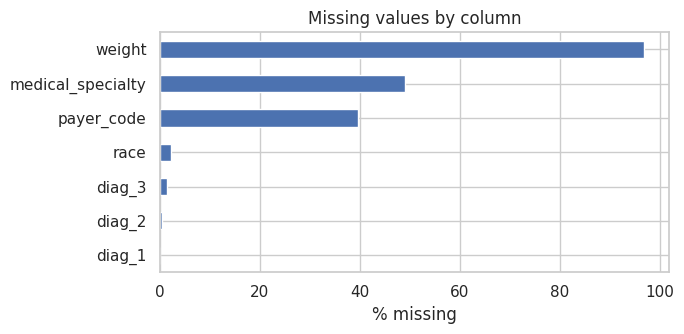

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
missing.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
plt.tight_layout()
plt.show()

`weight` is almost entirely missing, so it is not usable. `payer_code` and `medical_specialty` are missing for a large share of rows, but missingness itself may carry signal, so we will keep them with an explicit `Missing` category.

In [14]:
# Duplicates and patient structure
print("Duplicate encounter_id rows:", df_raw["encounter_id"].duplicated().sum())
print("Unique patients:", df_raw["patient_nbr"].nunique(), "of", len(df_raw), "encounters")
print("Patients with more than one encounter:", (df_raw["patient_nbr"].value_counts() > 1).sum())

Duplicate encounter_id rows: 0
Unique patients: 71518 of 101766 encounters
Patients with more than one encounter: 16773


## 3. Cleaning

Decisions, with reasons:

1. **Remove encounters ending in death or hospice** (discharge disposition 11, 13, 14, 19, 20, 21). Those patients cannot be readmitted, so keeping them would teach the model false "low risk" patterns.
2. **Keep one encounter per patient** (the first). Multiple encounters from the same patient are correlated, and putting them in both train and validation sets leaks information.
3. **Drop `weight`** (almost entirely missing) and the ID columns from modelling (kept for now so we can deduplicate).
4. **Drop rows with `Unknown/Invalid` gender** (a handful of rows).
5. **Treat ID-coded columns as categories**, not numbers (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`).

In [15]:
df = df_raw.copy()
n0 = len(df)

# 1. death / hospice
expired_or_hospice = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(expired_or_hospice)]
print(f"After removing death/hospice: {len(df)} (removed {n0 - len(df)})")

# 2. one encounter per patient (first by encounter_id)
n1 = len(df)
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
print(f"After keeping first encounter per patient: {len(df)} (removed {n1 - len(df)})")

# 3. weight
df = df.drop(columns=["weight"])

# 4. gender
n2 = len(df)
df = df[df["gender"].isin(["Male", "Female"])]
print(f"After removing unknown gender: {len(df)} (removed {n2 - len(df)})")

# 5. id-coded columns are categorical
for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[col] = df[col].astype(str)

df = df.reset_index(drop=True)
df.shape

After removing death/hospice: 99343 (removed 2423)
After keeping first encounter per patient: 69990 (removed 29353)
After removing unknown gender: 69987 (removed 3)


(69987, 49)

### Diagnosis codes

`diag_1`, `diag_2`, `diag_3` are ICD-9 codes with hundreds of distinct values. We group them into broad clinical categories (the grouping used in the original study by Strack et al., 2014).

In [16]:
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith(("V", "E")):
        return "Other"
    try:
        v = float(code)
    except ValueError:
        return "Other"
    if 250 <= v < 251:
        return "Diabetes"
    if (390 <= v <= 459) or v == 785:
        return "Circulatory"
    if (460 <= v <= 519) or v == 786:
        return "Respiratory"
    if (520 <= v <= 579) or v == 787:
        return "Digestive"
    if 800 <= v <= 999:
        return "Injury"
    if 710 <= v <= 739:
        return "Musculoskeletal"
    if (580 <= v <= 629) or v == 788:
        return "Genitourinary"
    if 140 <= v <= 239:
        return "Neoplasms"
    return "Other"


for c in ["diag_1", "diag_2", "diag_3"]:
    df[c + "_group"] = df[c].map(icd9_group)

df["diag_1_group"].value_counts()

,count
diag_1_group,
Circulatory,21389
Other,12124
Respiratory,9491
Digestive,6488
Diabetes,5748
Injury,4694
Musculoskeletal,4064
Genitourinary,3441
Neoplasms,2538


In [17]:
# Fill remaining missing categoricals with an explicit label
for c in ["race", "payer_code", "medical_specialty"]:
    df[c] = df[c].fillna("Missing")

# Medication columns: keep only those with some variation
drug_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
]
share_no = pd.Series({c: (df[c] == "No").mean() for c in drug_cols}).sort_values(ascending=False)
print("Share of patients with 'No' for each drug (higher = less informative):")
share_no.round(4)

Share of patients with 'No' for each drug (higher = less informative):


,0
examide,1.0000
glimepiride-pioglitazone,1.0000
citoglipton,1.0000
metformin-pioglitazone,1.0000
acetohexamide,1.0000
metformin-rosiglitazone,1.0000
troglitazone,1.0000
glipizide-metformin,0.9999
tolbutamide,0.9998
miglitol,0.9997


In [18]:
# Drugs prescribed to fewer than 1% of patients add almost nothing; flag them for removal in modelling
rare_drugs = share_no[share_no > 0.99].index.tolist()
print("Near-constant drug columns (>99% 'No'):", rare_drugs)

Near-constant drug columns (>99% 'No'): ['examide', 'glimepiride-pioglitazone', 'citoglipton', 'metformin-pioglitazone', 'acetohexamide', 'metformin-rosiglitazone', 'troglitazone', 'glipizide-metformin', 'tolbutamide', 'miglitol', 'tolazamide', 'chlorpropamide', 'acarbose', 'nateglinide', 'glyburide-metformin']


## 4. Target variable

`readmitted` has three values: `NO`, `>30` (readmitted after 30 days) and `<30` (readmitted within 30 days). Hospitals care about the `<30` group, so the target is binary: **1 if readmitted within 30 days, 0 otherwise**.

readmitted
NO     41476
>30    22226
<30     6285
Name: count, dtype: int64

Positive rate (readmitted <30 days): 9.0%


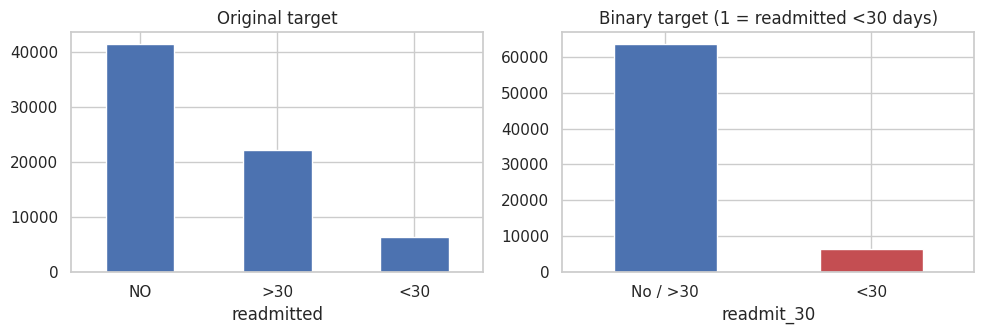

In [19]:
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

counts = df["readmitted"].value_counts()
print(counts)
print()
print(f"Positive rate (readmitted <30 days): {df['readmit_30'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
counts.plot.bar(ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_title("Original target")
df["readmit_30"].value_counts().sort_index().plot.bar(ax=axes[1], color=["#4C72B0", "#C44E52"], rot=0)
axes[1].set_title("Binary target (1 = readmitted <30 days)")
axes[1].set_xticklabels(["No / >30", "<30"])
plt.tight_layout()
plt.show()

The classes are imbalanced: the positive class is a small minority. Accuracy would be misleading (always predicting "not readmitted" scores high), so later we will use **ROC-AUC** and **PR-AUC**, and consider `class_weight` or threshold tuning.

## 5. Numeric features

In [20]:
num_cols = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69987.0,4.273336,2.933987,1.0,2.0,3.0,6.0,14.0
num_lab_procedures,69987.0,42.875863,19.894291,1.0,31.0,44.0,57.0,132.0
num_procedures,69987.0,1.425379,1.757003,0.0,0.0,1.0,2.0,6.0
num_medications,69987.0,15.665281,8.287321,1.0,10.0,14.0,20.0,81.0
number_outpatient,69987.0,0.279595,1.064108,0.0,0.0,0.0,0.0,42.0
number_emergency,69987.0,0.103905,0.511832,0.0,0.0,0.0,0.0,42.0
number_inpatient,69987.0,0.176276,0.601633,0.0,0.0,0.0,0.0,12.0
number_diagnoses,69987.0,7.224170,2.001257,1.0,6.0,8.0,9.0,16.0


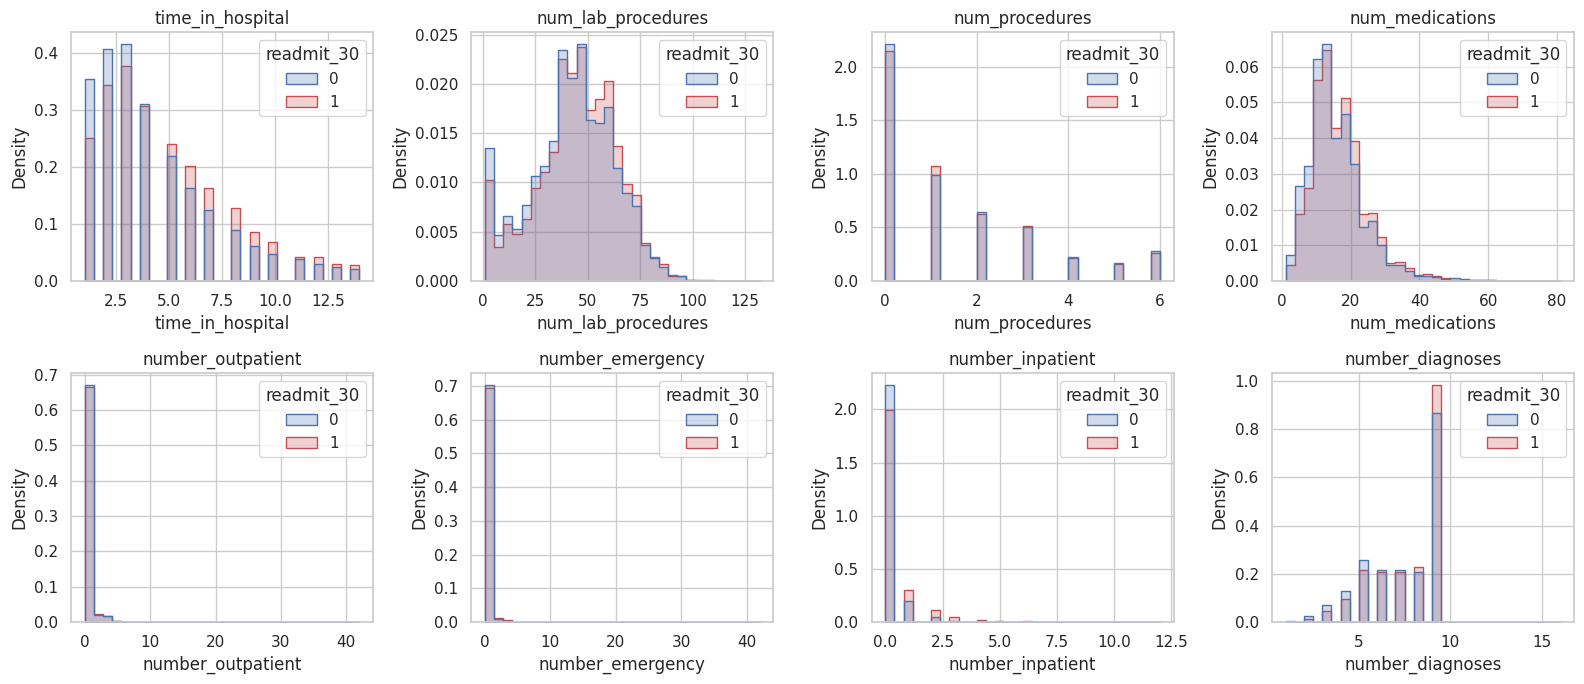

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue="readmit_30", stat="density", common_norm=False,
                 bins=30, element="step", ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [22]:
# Mean of each numeric feature by target, and readmission rate by prior inpatient visits
print(df.groupby("readmit_30")[num_cols].mean().round(2).T)

rate_by_inpatient = (
    df.assign(prior_inpatient=df["number_inpatient"].clip(upper=5))
      .groupby("prior_inpatient")["readmit_30"].agg(["mean", "size"])
)
rate_by_inpatient

readmit_30              0      1
time_in_hospital     4.22   4.79
num_lab_procedures  42.68  44.91
num_procedures       1.43   1.42
num_medications     15.57  16.62
number_outpatient    0.28   0.31
number_emergency     0.10   0.15
number_inpatient     0.16   0.37
number_diagnoses     7.20   7.51


,mean,size
prior_inpatient,,
0,0.081289,61792
1,0.128838,5798
2,0.185210,1501
3,0.237581,463
4,0.236842,228
5,0.356098,205


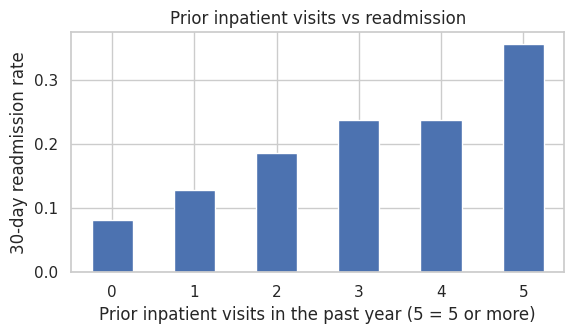

In [23]:
fig, ax = plt.subplots(figsize=(6, 3.5))
rate_by_inpatient["mean"].plot.bar(ax=ax, color="#4C72B0", rot=0)
ax.set_xlabel("Prior inpatient visits in the past year (5 = 5 or more)")
ax.set_ylabel("30-day readmission rate")
ax.set_title("Prior inpatient visits vs readmission")
plt.tight_layout()
plt.show()

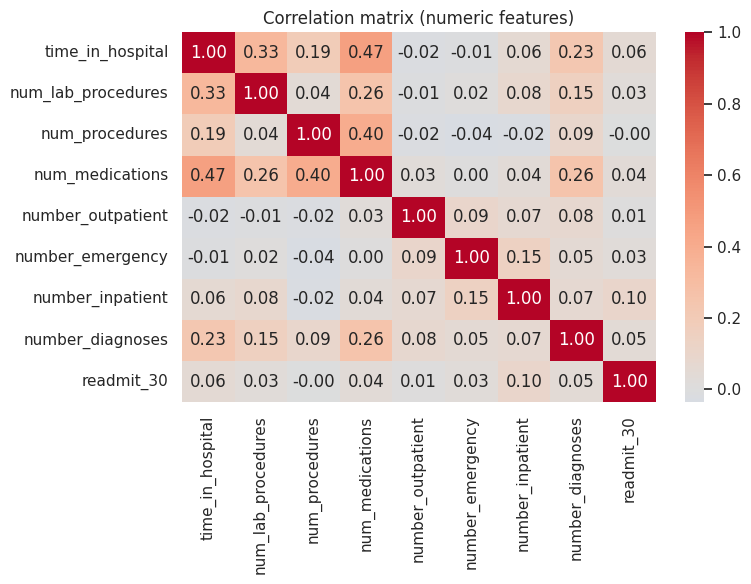

In [24]:
# Correlation between numeric features and the target
corr = df[num_cols + ["readmit_30"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

Counts such as `number_outpatient`, `number_emergency` and `number_inpatient` are heavily right-skewed. Tree-based models handle this without changes; for logistic regression we may cap or log-transform them.

## 6. Categorical features: readmission rate by category

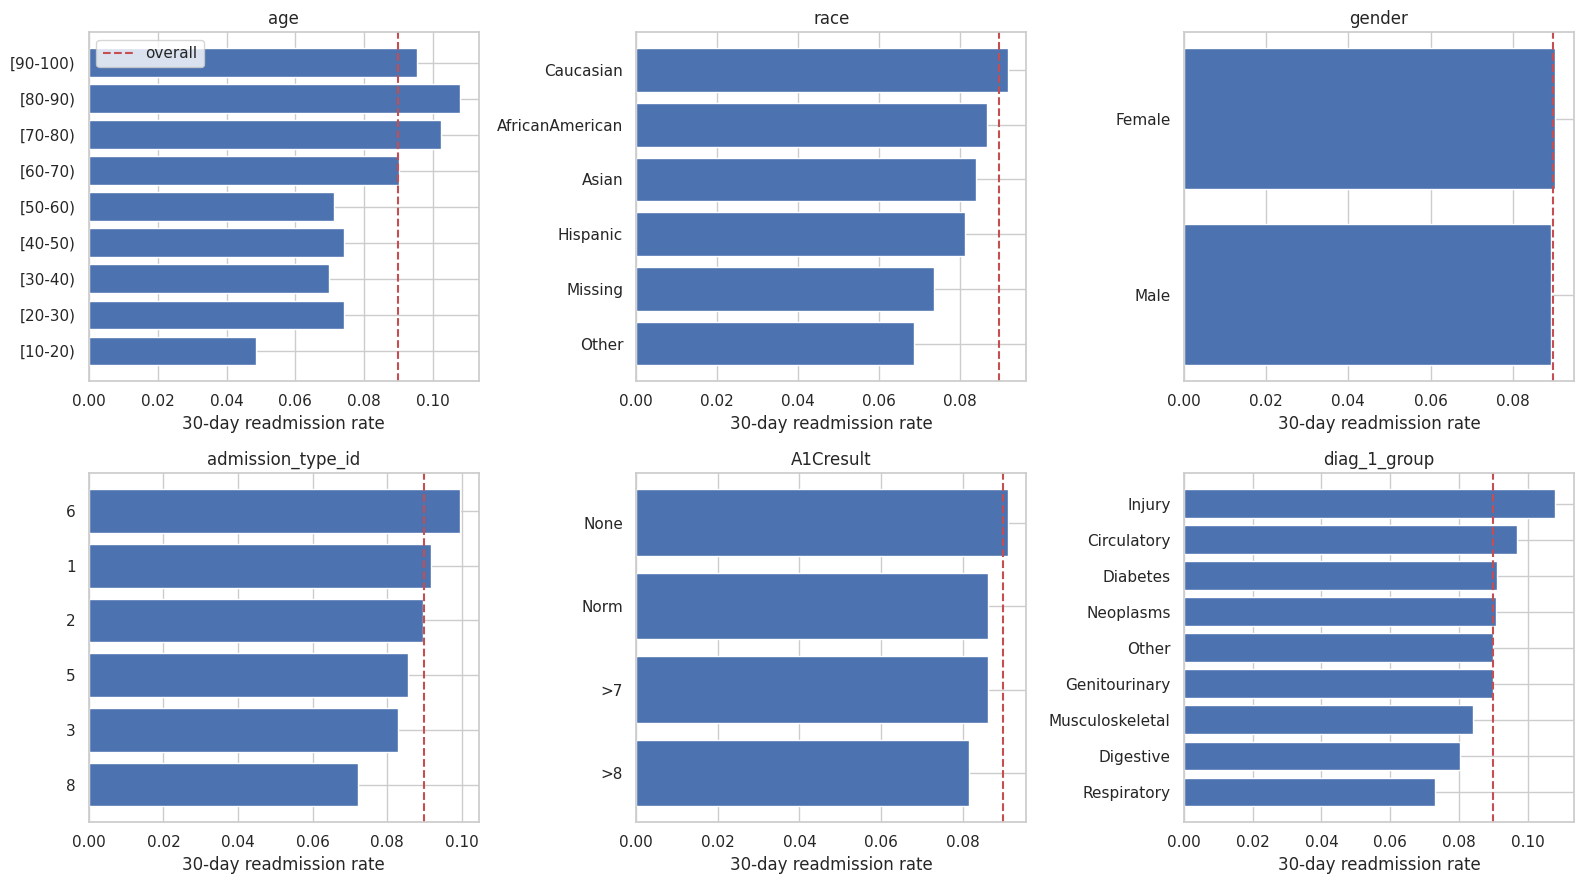

In [25]:
def rate_plot(col, order=None, ax=None, min_count=200):
    stats = df.groupby(col)["readmit_30"].agg(rate="mean", n="size")
    stats = stats[stats["n"] >= min_count]
    if order is not None:
        stats = stats.reindex([o for o in order if o in stats.index])
    else:
        stats = stats.sort_values("rate")
    ax = ax or plt.gca()
    ax.barh(stats.index.astype(str), stats["rate"], color="#4C72B0")
    ax.axvline(df["readmit_30"].mean(), color="#C44E52", ls="--", label="overall")
    ax.set_title(col)
    ax.set_xlabel("30-day readmission rate")
    return stats


age_order = sorted(df["age"].unique(), key=lambda s: int(s.strip("[]()").split("-")[0]))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
rate_plot("age", order=age_order, ax=axes[0, 0])
rate_plot("race", ax=axes[0, 1])
rate_plot("gender", ax=axes[0, 2])
rate_plot("admission_type_id", ax=axes[1, 0])
rate_plot("A1Cresult", ax=axes[1, 1])
rate_plot("diag_1_group", ax=axes[1, 2])
axes[0, 0].legend()
plt.tight_layout()
plt.show()

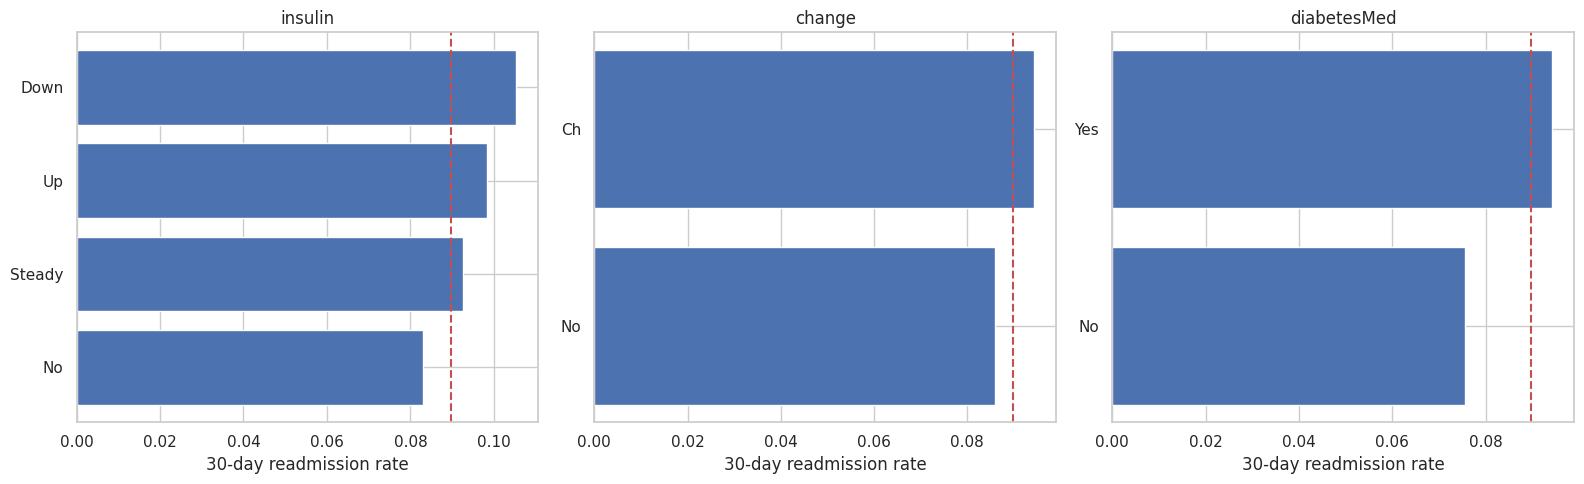

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
rate_plot("insulin", ax=axes[0])
rate_plot("change", ax=axes[1])
rate_plot("diabetesMed", ax=axes[2])
plt.tight_layout()
plt.show()

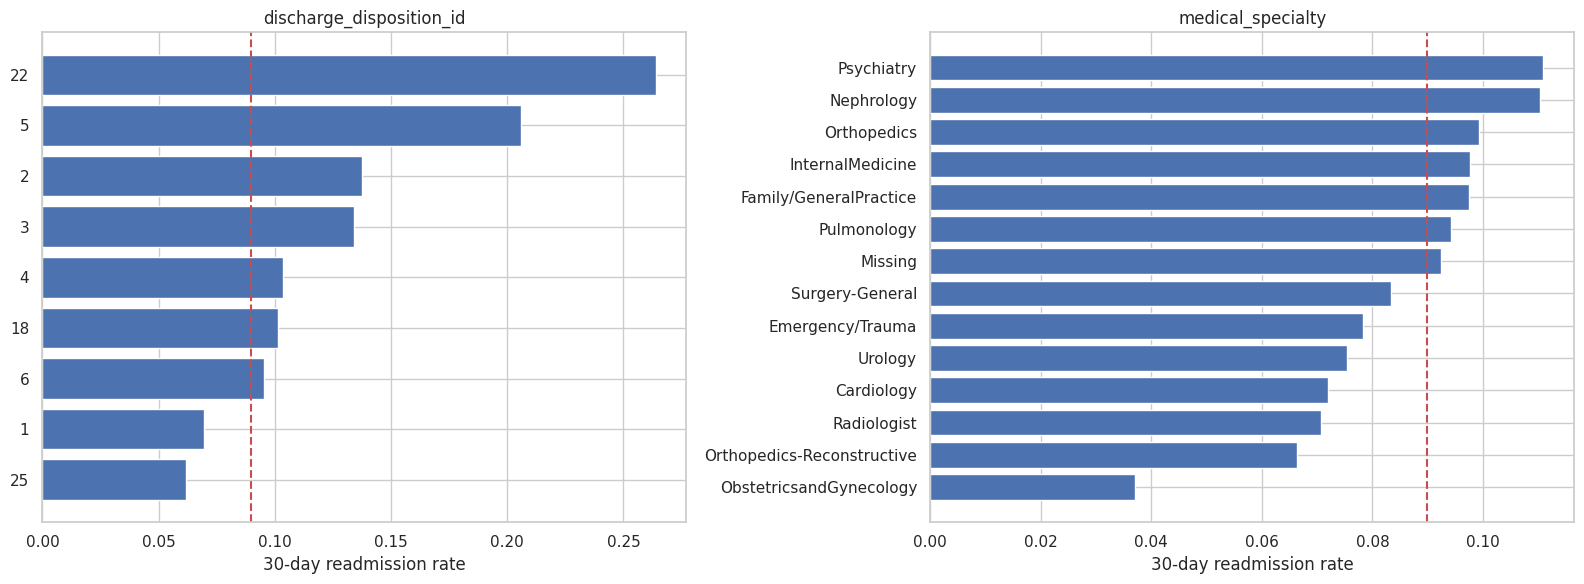

In [27]:
# Discharge disposition and medical specialty: many levels, so show the biggest groups only
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
rate_plot("discharge_disposition_id", ax=axes[0], min_count=500)
rate_plot("medical_specialty", ax=axes[1], min_count=500)
plt.tight_layout()
plt.show()

Admission and discharge IDs are codes. The meaning of each code is in `data/IDS_mapping.csv` (shipped in the UCI zip); for example, discharge to a skilled nursing facility or home health usually shows a higher readmission rate than discharge home.

## 7. Feature importance

Two complementary views:

1. **Mutual information** between each feature and the target (model-free, captures non-linear relationships).
2. **Permutation importance** from a quick random forest, measured on held-out data by the drop in ROC-AUC.

The random forest here is only a probe for importance, not the final model.

23 categorical, 8 numeric features


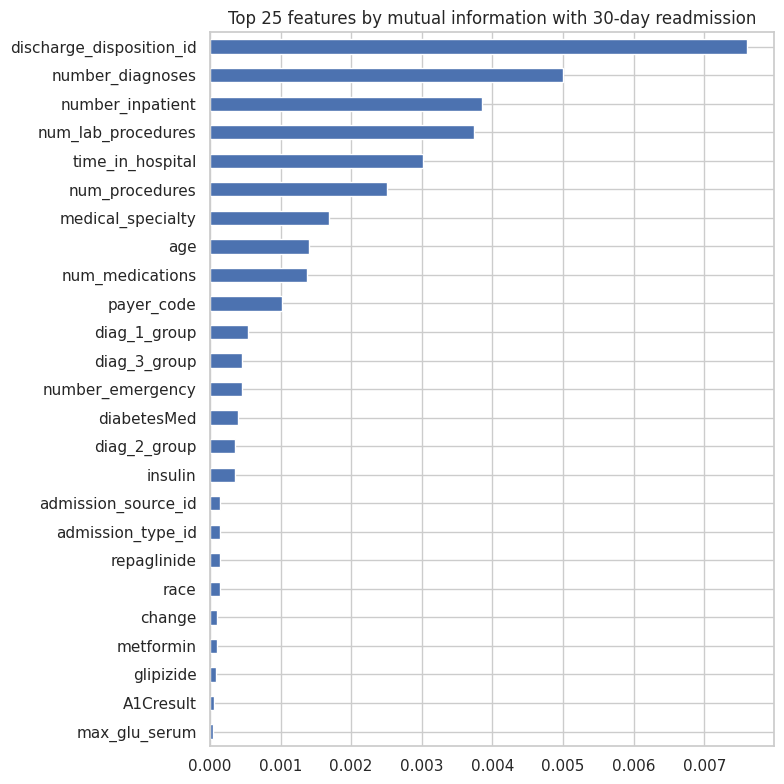

In [28]:
drop_for_model = (
    ["encounter_id", "patient_nbr", "readmitted", "readmit_30",
     "diag_1", "diag_2", "diag_3"] + rare_drugs
)
X = df.drop(columns=drop_for_model)
y = df["readmit_30"]

cat_features = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_features = [c for c in X.columns if c not in cat_features]
print(f"{len(cat_features)} categorical, {len(num_features)} numeric features")

X_enc = X.copy()
X_enc[cat_features] = OrdinalEncoder().fit_transform(X[cat_features].astype(str))
discrete_mask = [c in cat_features for c in X_enc.columns]

mi = mutual_info_classif(X_enc, y, discrete_features=discrete_mask, random_state=RANDOM_STATE)
mi_series = pd.Series(mi, index=X_enc.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
mi_series.head(25).sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Top 25 features by mutual information with 30-day readmission")
plt.tight_layout()
plt.show()

Probe random forest validation ROC-AUC: 0.648


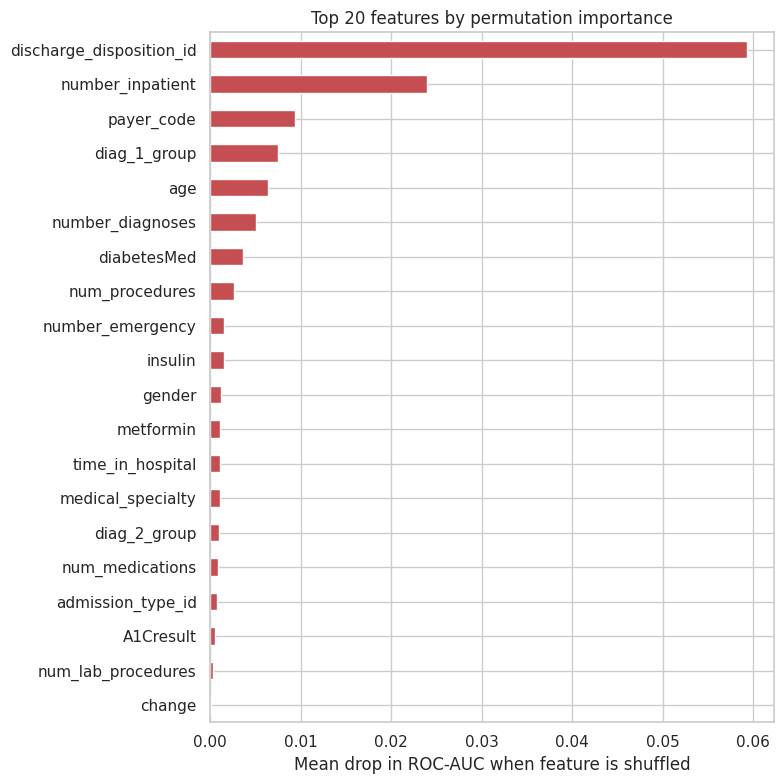

In [29]:
X_train, X_val, y_train, y_val = train_test_split(
    X_enc, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=20,
    class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

from sklearn.metrics import roc_auc_score
print(f"Probe random forest validation ROC-AUC: {roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]):.3f}")

# Permutation importance on up to 10,000 validation rows to keep it fast
val_sample = X_val.sample(min(10_000, len(X_val)), random_state=RANDOM_STATE)
perm = permutation_importance(
    rf, val_sample, y_val.loc[val_sample.index],
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
perm_series = pd.Series(perm.importances_mean, index=X_enc.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
perm_series.head(20).sort_values().plot.barh(ax=ax, color="#C44E52")
ax.set_xlabel("Mean drop in ROC-AUC when feature is shuffled")
ax.set_title("Top 20 features by permutation importance")
plt.tight_layout()
plt.show()

In [30]:
summary = pd.DataFrame({"mutual_info": mi_series, "permutation_importance": perm_series})
summary["mi_rank"] = summary["mutual_info"].rank(ascending=False)
summary["perm_rank"] = summary["permutation_importance"].rank(ascending=False)
summary.sort_values("perm_rank").head(15).round(4)

,mutual_info,permutation_importance,mi_rank,perm_rank
discharge_disposition_id,0.0076,0.0593,1.0,1.0
number_inpatient,0.0039,0.0239,3.0,2.0
payer_code,0.0010,0.0093,10.0,3.0
diag_1_group,0.0005,0.0075,11.0,4.0
age,0.0014,0.0064,8.0,5.0
number_diagnoses,0.0050,0.0051,2.0,6.0
diabetesMed,0.0004,0.0036,14.0,7.0
num_procedures,0.0025,0.0026,6.0,8.0
number_emergency,0.0004,0.0016,13.0,9.0
insulin,0.0003,0.0015,16.0,10.0


In [31]:
print(f"Cleaned size: {len(df):,} patients | positive rate: {df['readmit_30'].mean():.1%} "
      f"| positives: {df['readmit_30'].sum():,}")

print("\nTop 10 by permutation importance:")
print(summary.sort_values("perm_rank").head(10)[["mutual_info", "permutation_importance", "mi_rank", "perm_rank"]].round(4))

top_mi = set(mi_series.head(10).index)
top_perm = set(perm_series.head(10).index)
print("\nIn the top 10 of BOTH rankings:", sorted(top_mi & top_perm))

weak = summary[(summary["perm_rank"] > summary["perm_rank"].max() * 0.6) &
               (summary["permutation_importance"] <= 0.0005)]
print("\nLow signal (bottom ~40% by permutation importance and near-zero drop):")
print(weak.sort_values("permutation_importance").index.tolist())

print("\nSkewness of numeric features (above ~1 = strongly right-skewed):")
print(X[num_features].skew().sort_values(ascending=False).round(2))

Cleaned size: 69,987 patients | positive rate: 9.0% | positives: 6,285

Top 10 by permutation importance:
                          mutual_info  permutation_importance  mi_rank  \
discharge_disposition_id       0.0076                  0.0593      1.0   
number_inpatient               0.0039                  0.0239      3.0   
payer_code                     0.0010                  0.0093     10.0   
diag_1_group                   0.0005                  0.0075     11.0   
age                            0.0014                  0.0064      8.0   
number_diagnoses               0.0050                  0.0051      2.0   
diabetesMed                    0.0004                  0.0036     14.0   
num_procedures                 0.0025                  0.0026      6.0   
number_emergency               0.0004                  0.0016     13.0   
insulin                        0.0003                  0.0015     16.0   

                          perm_rank  
discharge_disposition_id        1.0  
num

## 8. Takeaways


## 8. Takeaways

**Data size and baseline.** After cleaning, 69,987 patients remain, and 6,285 of them (9.0%) were readmitted within 30 days. A model with no skill would score a PR-AUC of about 0.09, so that is the baseline to beat. With only about 1 patient in 11 positive, I judge models by PR-AUC, ROC-AUC and lift, not accuracy.

**Strongest features.** Six features rank in the top 10 of both mutual information and permutation importance: `discharge_disposition_id`, `number_inpatient`, `number_diagnoses`, `age`, `payer_code` and `num_procedures`. The two methods agree on the set but not the order (`number_diagnoses` is 2nd by mutual information but 6th by permutation importance).
`discharge_disposition_id` stands out: shuffling it lowers ROC-AUC by about 0.059, roughly 2.5 times the next feature (`number_inpatient`, 0.024). After the top two, importances drop quickly, so ranks 7 to 10 are close to tied.
Taken together, the signal is mostly about where the patient goes after discharge and how much hospital care they have needed before (previous inpatient visits, number of diagnoses and procedures), rather than individual lab results. `payer_code` ranks 3rd by permutation importance. It contains a large "Missing" category and likely reflects insurance type or differences in how hospitals record data rather than anything clinical, so I treat it with caution.

**Low-signal features.** Shuffling these barely changes the score: `number_outpatient`, `admission_source_id`, `diag_3_group`, `max_glu_serum`, `race`, `change`, `num_lab_procedures`, and six individual drug columns (`glimepiride`, `glyburide`, `pioglitazone`, `glipizide`, `repaglinide`, `rosiglitazone`). Dropping them would simplify the model. However, permutation importance can understate features that overlap with others (for example `change` with `diabetesMed` and `insulin`, or `num_lab_procedures` with `time_in_hospital`), so I keep them for now and, if time allows, will compare cross-validated PR-AUC with and without them.

**Skewed features.** `number_emergency` (skew 21.2), `number_outpatient` (9.7) and `number_inpatient` (5.6) are extremely right-skewed: most patients have zero prior visits and a few have many. I apply `log1p` to these for logistic regression, and tree models are unaffected. `num_medications`, `num_procedures` and `time_in_hospital` are only mildly skewed (1.2 to 1.4) and are left as they are.

**Next:** train a logistic regression baseline, random forest and XGBoost/LightGBM, tune them, pick the best by validation PR-AUC/ROC-AUC, and move the final training code into `train.py`.

## 9. Model training

**Plan**

1. Hold out 20% of the data as a **test set** that is touched only once, at the end.
2. On the remaining 80%, compare a dummy baseline, logistic regression (linear), random forest and XGBoost (tree-based) with 5-fold cross-validation.
3. Tune each real model with randomized search, scoring by **PR-AUC** (average precision), which suits the imbalanced target better than accuracy or ROC-AUC alone.
4. Pick the best model by **cross-validated** score (not by test score), then report test performance.

Set `FAST = True` for a quick smoke run (few search iterations). The full run with `FAST = False` can take a while on ~70k rows.

In [32]:
import json
import time

from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

FAST = False          # True = quick smoke test
N_ITER = 4 if FAST else 20
CV_FOLDS_TUNING = 3

In [33]:
from sklearn.model_selection import train_test_split

# X, y, cat_features and num_features come from the feature-importance section.
# X is the cleaned, un-encoded feature table (IDs, raw ICD-9 codes and near-constant drugs removed).
X_full, X_test, y_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train+validation: {len(X_full)} rows, positive rate {y_full.mean():.3f}")
print(f"Test:             {len(X_test)} rows, positive rate {y_test.mean():.3f}")

Train+validation: 55989 rows, positive rate 0.090
Test:             13998 rows, positive rate 0.090


### Preprocessing

- **Linear model:** standardize numeric features, apply `log1p` to the skewed visit-count features first, one-hot encode categoricals (rare levels are grouped into an "infrequent" bucket).
- **Tree models:** numeric features pass through unchanged; same one-hot encoding for categoricals.

Everything lives inside a scikit-learn `Pipeline`, so scaling and encoding are fitted on training folds only (no leakage during cross-validation) and the pipeline can be pickled and served as one object.

In [34]:
skewed = ["number_outpatient", "number_emergency", "number_inpatient"]
other_num = [c for c in num_features if c not in skewed]


def make_preprocessor(kind):
    cat = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30)
    if kind == "linear":
        return ColumnTransformer([
            ("skewed", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), skewed),
            ("num", StandardScaler(), other_num),
            ("cat", cat, cat_features),
        ])
    return ColumnTransformer([
        ("num", "passthrough", num_features),
        ("cat", cat, cat_features),
    ])


neg, pos = (y_full == 0).sum(), (y_full == 1).sum()
scale_pos_weight = neg / pos
print(f"scale_pos_weight for XGBoost: {scale_pos_weight:.1f}")

pipelines = {
    "dummy (prior)": Pipeline([
        ("prep", make_preprocessor("tree")),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "logistic regression": Pipeline([
        ("prep", make_preprocessor("linear")),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]),
    "random forest": Pipeline([
        ("prep", make_preprocessor("tree")),
        ("model", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=20, class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    "xgboost": Pipeline([
        ("prep", make_preprocessor("tree")),
        ("model", XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
            colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
            eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
}

scale_pos_weight for XGBoost: 10.1


### Step 1: default-parameter comparison (5-fold CV)

In [35]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name, pipe in pipelines.items():
    t0 = time.time()
    res = cross_validate(pipe, X_full, y_full, cv=cv5, scoring=scoring, n_jobs=1)
    rows.append({
        "model": name,
        "roc_auc": res["test_roc_auc"].mean(), "roc_auc_std": res["test_roc_auc"].std(),
        "pr_auc": res["test_pr_auc"].mean(), "pr_auc_std": res["test_pr_auc"].std(),
        "seconds": time.time() - t0,
    })
    print(f"{name:22s} ROC-AUC {rows[-1]['roc_auc']:.3f}  PR-AUC {rows[-1]['pr_auc']:.3f}  ({rows[-1]['seconds']:.0f}s)")

baseline_results = pd.DataFrame(rows).set_index("model").round(4)
baseline_results

dummy (prior)          ROC-AUC 0.500  PR-AUC 0.090  (8s)
logistic regression    ROC-AUC 0.648  PR-AUC 0.165  (16s)
random forest          ROC-AUC 0.655  PR-AUC 0.173  (245s)
xgboost                ROC-AUC 0.654  PR-AUC 0.178  (19s)


,roc_auc,roc_auc_std,pr_auc,pr_auc_std,seconds
model,,,,,
dummy (prior),0.5000,0.0000,0.0898,0.0000,7.6002
logistic regression,0.6484,0.0034,0.1653,0.0041,16.1432
random forest,0.6552,0.0067,0.1727,0.0073,245.1230
xgboost,0.6543,0.0057,0.1779,0.0076,18.5334


The dummy model's PR-AUC equals the positive rate, which is the floor any useful model must beat. ROC-AUC of 0.5 is chance.

### Step 2: hyperparameter tuning

Randomized search with 3-fold CV, optimizing PR-AUC.

| Model | Parameters tuned |
|---|---|
| Logistic regression | regularization strength `C` |
| Random forest | number of trees, depth, min samples per leaf, features per split |
| XGBoost | trees, learning rate, depth, min child weight, row/column subsampling, L2 regularization |

In [46]:
from types import SimpleNamespace
from sklearn.base import clone

# XGBoost parameters found by the earlier full-data search
xgb_full_params = {
    "model__colsample_bytree": 0.7201, "model__learning_rate": 0.0144, "model__max_depth": 6,
    "model__min_child_weight": 8, "model__n_estimators": 580, "model__reg_lambda": 0.2506,
    "model__subsample": 0.7564,
}
lr_params = searches["logistic regression"].best_params_

finalists = {
    "logistic regression": (clone(pipelines["logistic regression"]).set_params(**lr_params), lr_params),
    "xgboost": (clone(pipelines["xgboost"]).set_params(**xgb_full_params), xgb_full_params),
}

# Same 5 folds and the same (full) training data for both finalists
final_cv = {}
for name, (pipe, _) in finalists.items():
    t0 = time.time()
    res = cross_validate(pipe, X_full, y_full, cv=cv5, scoring=scoring, n_jobs=1)
    final_cv[name] = res
    print(f"{name:22s} PR-AUC {res['test_pr_auc'].mean():.4f} +/- {res['test_pr_auc'].std():.4f}   "
          f"ROC-AUC {res['test_roc_auc'].mean():.4f}   ({time.time() - t0:.0f}s)")

# Decision rule, fixed before looking at the test set:
# pick XGBoost only if its mean CV PR-AUC beats logistic regression by more than the larger
# fold-to-fold standard deviation; otherwise keep the simpler linear model.
lr_m, xgb_m = (final_cv[n]["test_pr_auc"].mean() for n in ("logistic regression", "xgboost"))
margin = max(final_cv[n]["test_pr_auc"].std() for n in final_cv)
chosen = "xgboost" if (xgb_m - lr_m) > margin else "logistic regression"
print(f"\nDifference (XGBoost - LR): {xgb_m - lr_m:+.4f}  | noise margin: {margin:.4f}  ->  chosen: {chosen}")

# Refit both finalists on all training rows and register them so the test-set cells below work unchanged
for name, (pipe, params) in finalists.items():
    pipe.fit(X_full, y_full)
    searches[name] = SimpleNamespace(
        best_estimator_=pipe, best_params_=params,
        best_score_=float(final_cv[name]["test_pr_auc"].mean()),
    )

logistic regression    PR-AUC 0.1653 +/- 0.0042   ROC-AUC 0.6481   (22s)
xgboost                PR-AUC 0.1839 +/- 0.0091   ROC-AUC 0.6568   (31s)

Difference (XGBoost - LR): +0.0186  | noise margin: 0.0091  ->  chosen: xgboost


In [37]:
TUNE_ROWS = 25_000   # tune on a subsample, then refit each winner on ALL training rows
N_ITER = 8           # random parameter combinations tried per model

if len(X_full) > TUNE_ROWS:
    X_tune, _, y_tune, _ = train_test_split(
        X_full, y_full, train_size=TUNE_ROWS, stratify=y_full, random_state=RANDOM_STATE
    )
else:
    X_tune, y_tune = X_full, y_full
print(f"Tuning on {len(X_tune):,} rows (positive rate {y_tune.mean():.3f}); final fits use {len(X_full):,} rows")

param_spaces = {
    "logistic regression": {
        "model__C": loguniform(1e-3, 10),
    },
    "random forest": {
        "model__n_estimators": randint(100, 250),
        "model__max_depth": randint(6, 16),
        "model__min_samples_leaf": randint(10, 60),
        "model__max_features": ["sqrt", "log2", 0.3],
    },
    "xgboost": {
        "model__n_estimators": randint(150, 500),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 8),
        "model__min_child_weight": randint(1, 30),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_lambda": loguniform(0.1, 20),
    },
}

cv_tune = StratifiedKFold(n_splits=CV_FOLDS_TUNING, shuffle=True, random_state=RANDOM_STATE)

# Keep results from any model that already finished, so re-running this cell resumes
if "searches" not in globals():
    searches = {}

for name, space in param_spaces.items():
    if name in searches:
        print(f"{name:22s} already done, skipping")
        continue
    t0 = time.time()
    search = RandomizedSearchCV(
        pipelines[name], space, n_iter=N_ITER, scoring="average_precision",
        cv=cv_tune, n_jobs=1, refit=True, random_state=RANDOM_STATE, verbose=1,
    )
    search.fit(X_tune, y_tune)
    if len(X_tune) < len(X_full):
        search.best_estimator_.fit(X_full, y_full)   # refit the best configuration on all training data
    searches[name] = search
    print(f"{name:22s} best CV PR-AUC {search.best_score_:.4f}  ({time.time() - t0:.0f}s)")
    print("   ", {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                  for k, v in search.best_params_.items()})

Tuning on 25,000 rows (positive rate 0.090); final fits use 55,989 rows
logistic regression    already done, skipping
Fitting 3 folds for each of 8 candidates, totalling 24 fits
random forest          best CV PR-AUC 0.1618  (260s)
    {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 24, 'n_estimators': 206}
Fitting 3 folds for each of 8 candidates, totalling 24 fits
xgboost                best CV PR-AUC 0.1631  (48s)
    {'colsample_bytree': np.float64(0.5035), 'learning_rate': np.float64(0.0107), 'max_depth': 4, 'min_child_weight': 27, 'n_estimators': 319, 'reg_lambda': np.float64(0.128), 'subsample': np.float64(0.9895)}


In [47]:
import pandas as pd

# Compare default vs tuned CV PR-AUC (note: 5-fold default vs 3-fold tuned, so treat small gaps with caution)
compare = pd.DataFrame({
    "default_pr_auc": baseline_results["pr_auc"].drop("dummy (prior)"),
    "tuned_pr_auc": pd.Series({n: s.best_score_ for n, s in searches.items()}),
}).round(4)
compare["gain"] = (compare["tuned_pr_auc"] - compare["default_pr_auc"]).round(4)
compare

,default_pr_auc,tuned_pr_auc,gain
logistic regression,0.1653,0.1653,0.0000
random forest,0.1727,0.1618,-0.0109
xgboost,0.1779,0.1839,0.0060


### Step 3: select the best model and evaluate once on the test set

The winner is chosen by cross-validated PR-AUC. The test set is used only to report how that choice generalizes.

In [48]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print(f"Selected model: {best_name}")

test_rows = []
test_probs = {}
for name, search in searches.items():
    p = search.best_estimator_.predict_proba(X_test)[:, 1]
    test_probs[name] = p
    test_rows.append({
        "model": name,
        "cv_pr_auc": search.best_score_,
        "test_roc_auc": roc_auc_score(y_test, p),
        "test_pr_auc": average_precision_score(y_test, p),
    })
test_results = pd.DataFrame(test_rows).set_index("model").round(4)
print(f"Test positive rate (PR-AUC of a random model): {y_test.mean():.3f}")
test_results

Selected model: xgboost
Test positive rate (PR-AUC of a random model): 0.090


,cv_pr_auc,test_roc_auc,test_pr_auc
model,,,
logistic regression,0.1653,0.6511,0.1716
random forest,0.1618,0.6569,0.1773
xgboost,0.1839,0.6557,0.1911


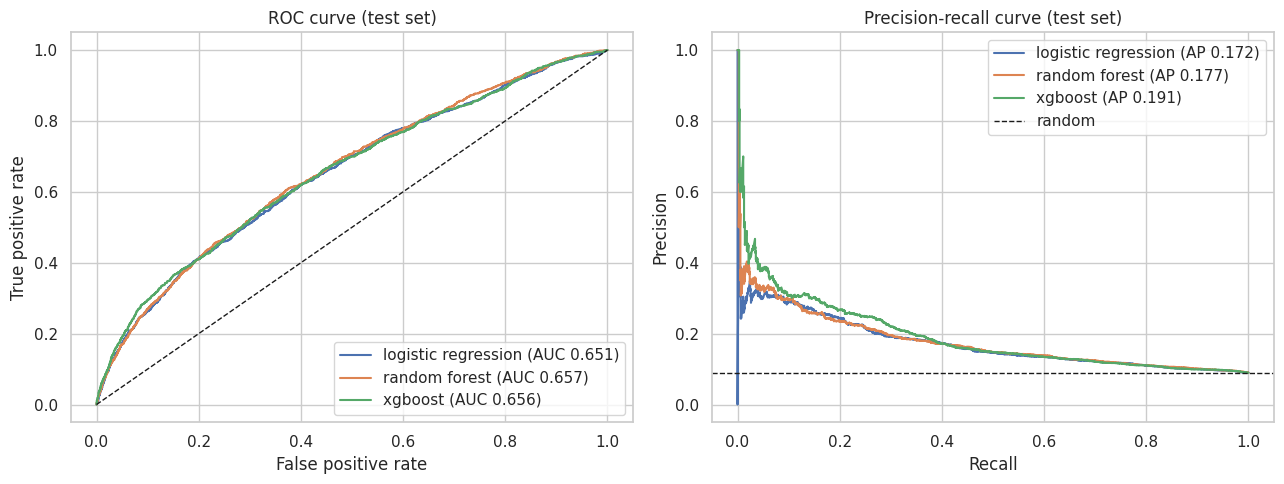

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test set)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="random")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test set)")
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

### Step 4: what the model means in practice

A hospital cannot follow up with every patient. The useful question is: *if we flag the highest-risk X% of discharges, how many of the real 30-day readmissions do we catch, compared with picking patients at random?*

In [51]:
p_best = test_probs[best_name]
order = np.argsort(-p_best)
y_sorted = y_test.to_numpy()[order]
total_pos = y_sorted.sum()
base_rate = y_test.mean()

rows = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(len(y_sorted) * frac)
    caught = y_sorted[:k].sum()
    rows.append({
        "flag top % of patients": int(frac * 100),
        "patients flagged": k,
        "precision": caught / k,
        "recall (readmissions caught)": caught / total_pos,
        "lift vs random": (caught / k) / base_rate,
    })
pd.DataFrame(rows).round(3)

,flag top % of patients,patients flagged,precision,recall (readmissions caught),lift vs random
0,5,699,0.290,0.161,3.234
1,10,1399,0.243,0.270,2.706
2,20,2799,0.175,0.391,1.953
3,30,4199,0.149,0.496,1.655
4,50,6999,0.123,0.687,1.375


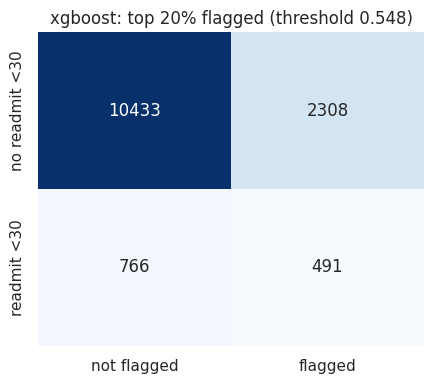

In [52]:
# Confusion matrix when flagging the top 20% of patients
k = int(len(y_sorted) * 0.20)
threshold = np.sort(p_best)[::-1][k - 1]
y_pred = (p_best >= threshold).astype(int)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["not flagged", "flagged"], yticklabels=["no readmit <30", "readmit <30"])
ax.set_title(f"{best_name}: top 20% flagged (threshold {threshold:.3f})")
plt.tight_layout()
plt.show()

In [53]:
# Save the chosen configuration so train.py can reproduce it
final_config = {
    "model": best_name,
    "best_params": searches[best_name].best_params_,
    "cv_pr_auc": searches[best_name].best_score_,
    "test_roc_auc": float(roc_auc_score(y_test, p_best)),
    "test_pr_auc": float(average_precision_score(y_test, p_best)),
    "flag_threshold_top20pct": float(threshold),
}
with open("best_params.json", "w") as f:
    json.dump(final_config, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
final_config

{'model': 'xgboost',
 'best_params': {'model__colsample_bytree': 0.7201,
  'model__learning_rate': 0.0144,
  'model__max_depth': 6,
  'model__min_child_weight': 8,
  'model__n_estimators': 580,
  'model__reg_lambda': 0.2506,
  'model__subsample': 0.7564},
 'cv_pr_auc': 0.18386313123301476,
 'test_roc_auc': 0.6557253167678159,
 'test_pr_auc': 0.19112682427755479,
 'flag_threshold_top20pct': 0.5477218627929688}

In [54]:
pretty = {"logistic regression": "Logistic regression", "random forest": "Random forest", "xgboost": "XGBoost"}
lines = ["| Model | CV PR-AUC | Test ROC-AUC | Test PR-AUC |", "|---|---|---|---|"]
lines.append(f"| Dummy (always predicts the base rate) | {baseline_results.loc['dummy (prior)', 'pr_auc']:.3f} | 0.500 | {y_test.mean():.3f} |")
for name, r in test_results.iterrows():
    tag = " (selected)" if name == best_name else ""
    lines.append(f"| {pretty.get(name, name)}{tag} | {r['cv_pr_auc']:.3f} | {r['test_roc_auc']:.3f} | {r['test_pr_auc']:.3f} |")
print("\n".join(lines))

k20 = int(len(y_sorted) * 0.20)
caught20 = y_sorted[:k20].sum()
print()
print(f"Selected model: {pretty.get(best_name, best_name)}")
print(f"Flagging the top 20% of patients ({k20:,} of {len(y_sorted):,} in the test set) catches "
      f"{caught20 / total_pos:.0%} of the readmissions. Precision among flagged patients is "
      f"{caught20 / k20:.1%} against a base rate of {base_rate:.1%}, a lift of {(caught20 / k20) / base_rate:.2f}x.")

| Model | CV PR-AUC | Test ROC-AUC | Test PR-AUC |
|---|---|---|---|
| Dummy (always predicts the base rate) | 0.090 | 0.500 | 0.090 |
| Logistic regression | 0.165 | 0.651 | 0.172 |
| Random forest | 0.162 | 0.657 | 0.177 |
| XGBoost (selected) | 0.184 | 0.656 | 0.191 |

Selected model: XGBoost
Flagging the top 20% of patients (2,799 of 13,998 in the test set) catches 39% of the readmissions. Precision among flagged patients is 17.5% against a base rate of 9.0%, a lift of 1.95x.


### Model selection summary
### Model selection summary

- **Winner:** XGBoost. In a head-to-head on all training rows (5-fold CV), it scored PR-AUC 0.184 ± 0.009 against 0.165 ± 0.004 for logistic regression. The 0.019 gap is about twice the fold-to-fold spread, so I treat it as real. The rule was fixed beforehand: XGBoost had to beat logistic regression by more than the larger fold standard deviation, otherwise the simpler model would stay. The random forest was tuned on a 25,000-row subsample for time, so its tuned CV score (0.162) is not comparable. Untuned, it scored 0.173 on all training rows, so it is probably close to but slightly behind XGBoost, and it was not a finalist.
- **Effect of tuning:** tuning made little difference. Logistic regression did not change (0.165 before and after), and XGBoost gained 0.006 (0.178 to 0.184), which is smaller than the fold-to-fold spread (about 0.009), so I treat it as a small or uncertain improvement. The random forest's tuned score is lower than its default (0.162 vs 0.173), but that is an artifact of tuning on a subsample, not a real loss. Untuned XGBoost (0.178) already beat both untuned alternatives, so the model family mattered more than the parameters.
- **Test set:** XGBoost reached ROC-AUC 0.656 and PR-AUC 0.191 against 0.090 for a random model, so it ranks patients clearly better than chance. The test PR-AUC (0.191) is close to the CV score (0.184), so there is no sign of overfitting.
- **Practical value:** on the test set (13,998 patients, 9.0% readmitted), flagging the top 10% by predicted risk (1,399 patients) catches 27% of the readmissions at 24.3% precision, a lift of 2.7x over random selection. Flagging the top 20% (2,799 patients) catches 39% at 17.5% precision (lift 1.95x), and the top 5% reaches a lift of 3.2x. Lift falls as more patients are flagged, so the best use of limited follow-up capacity is to concentrate it on the highest-risk few.

**Next:** move the final training logic into `train.py` (it should read `best_params.json` or hard-code the chosen parameters, fit on all of the training data, and pickle the pipeline), then write `predict.py`.

In [56]:
!python --version
!pip list 2>/dev/null | grep -iE "scikit-learn|xgboost|pandas|numpy"

Python 3.13.18
geopandas                             1.2.0
numpy                                 2.4.6
pandas                                2.2.3
pandas-datareader                     0.11.1
pandas-gbq                            0.30.0
pandas-stubs                          2.2.3.250527
scikit-learn                          1.6.1
sklearn-pandas                        2.2.0
xgboost                               3.4.1


In [57]:
!ls /content

best_params.json  data	features.py  sample_data  train.py


In [58]:
!python train.py

Loading and cleaning data...
/content/features.py:105: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(csv_path, na_values=["?"], keep_default_na=False)
69987 patients, 31 features, positive rate 0.090
Training xgboost...
Test ROC-AUC: 0.656   Test PR-AUC: 0.191 (random baseline 0.090)
High-risk threshold (top 20%): 0.5476
Saved model to model.bin


In [61]:
from google.colab import files
files.download("model.bin")
!pip list 2>/dev/null | grep -iE "scikit-learn|xgboost|pandas|numpy"

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

geopandas                             1.2.0
numpy                                 2.4.6
pandas                                2.2.3
pandas-datareader                     0.11.1
pandas-gbq                            0.30.0
pandas-stubs                          2.2.3.250527
scikit-learn                          1.6.1
sklearn-pandas                        2.2.0
xgboost                               3.4.1


In [62]:
from google.colab import files
files.download("model.bin")
!pip list 2>/dev/null | grep -iE "scikit-learn|xgboost|pandas|numpy"

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

geopandas                             1.2.0
numpy                                 2.4.6
pandas                                2.2.3
pandas-datareader                     0.11.1
pandas-gbq                            0.30.0
pandas-stubs                          2.2.3.250527
scikit-learn                          1.6.1
sklearn-pandas                        2.2.0
xgboost                               3.4.1
